# EdamamePipeline API Demo

This notebook demonstrates how to use the EdamamePipeline API for model inference.

## Installation

Make sure you have the required dependencies installed and have trained a model checkpoint.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sys import path

path.append("../")
from edamame.pipeline import EdamamePipeline
from edamame.utils.sample_scaling import mean_scaling

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

## 1. Load a Pretrained Model

The API supports multiple ways to load models. Here we'll use the most straightforward approach.

In [2]:
# Check if checkpoint exists
checkpoint_path = "../checkpoints.nosync/edamame.model.efficientnet_contrastive.EfficientNetContrastive__edamame.model.loss.contrastive.NCELossCorrected__['APSync', 'BiHeartS', 'CLUES', 'HeartS', 'LAUREATE', 'M2Sleep']_60s/current_best.ckpt"
if not Path(checkpoint_path).exists():
    print(f"⚠️  Checkpoint not found: {checkpoint_path}")
    print("Please ensure you have a trained model checkpoint.")
else:
    print(f"✓ Checkpoint found: {checkpoint_path}")

# Load the model
pipeline = EdamamePipeline.from_pretrained(
    model_name="efficientnet",
    weights_path=checkpoint_path,
    device_map="auto",  # Use GPU if available
    torch_dtype=torch.float32,
    normalization_fn=mean_scaling,
)

print(f"\nLoaded pipeline:")
print(pipeline)

✓ Checkpoint found: ../checkpoints.nosync/edamame.model.efficientnet_contrastive.EfficientNetContrastive__edamame.model.loss.contrastive.NCELossCorrected__['APSync', 'BiHeartS', 'CLUES', 'HeartS', 'LAUREATE', 'M2Sleep']_60s/current_best.ckpt

Loaded pipeline:
EdamamePipeline(
  model_name=efficientnet,
  device=cpu,
  model=EfficientNetContrastive
)


## 2. Load Real EDA Data

Let's load real EDA time series data from the dataset.

In [3]:
# Load real EDA data
data_path = "/Users/leonardoalchieri/Desktop/GIT-Mine/eda-foundation-models/data.nosync/60s/APSync/data_unknown_60s.npz"

print(f"Loading data from: {data_path}")

print(f"✓ Data file found!")

# Load the npz file
data = np.load(data_path)

# Inspect the contents
print(f"\nAvailable keys in the npz file: {list(data.keys())}")

# Load the data array (assuming it's stored with key 'data' or 'arr_0')
if 'data' in data.keys():
    eda_data = data['data']
elif 'arr_0' in data.keys():
    eda_data = data['arr_0']
elif 'values' in data.keys():
    eda_data = data['values']
else:
    eda_data = data[list(data.keys())[0]]

print(f"Original data shape: {eda_data.shape}")
print(f"Data dtype: {eda_data.dtype}")

# Convert to torch tensor
# Expected shape: (num_samples, seq_len) or (num_samples, seq_len, channels)
if len(eda_data.shape) == 2:
    # Add channel dimension if not present
    eda_data = np.expand_dims(eda_data, axis=-1)

batch_data = torch.from_numpy(eda_data).float()

# Take first 4 samples for demonstration
# Take one random sample
batch_size = 1
rand_idx = np.random.randint(0, batch_data.shape[0])
print(f"Selected random sample index: {rand_idx}")
# Keep batch dimension
batch_data = batch_data[[rand_idx]]
batch_data = batch_data[:batch_size]

seq_len = batch_data.shape[1]
in_channels = batch_data.shape[2]
time = np.linspace(0, 60, seq_len)

print(f"\nBatch data shape: {batch_data.shape}")
print(f"Data range: [{batch_data.min():.3f}, {batch_data.max():.3f}]")
print(f"Batch size: {batch_size}, Sequence length: {seq_len}, Channels: {in_channels}")

Loading data from: /Users/leonardoalchieri/Desktop/GIT-Mine/eda-foundation-models/data.nosync/60s/APSync/data_unknown_60s.npz
✓ Data file found!

Available keys in the npz file: ['values', 'groups', 'name']
Original data shape: (10042, 240, 3)
Data dtype: float64
Selected random sample index: 7270

Batch data shape: torch.Size([1, 240, 3])
Data range: [-0.206, 0.459]
Batch size: 1, Sequence length: 240, Channels: 3


In [4]:
batch_data = batch_data[..., [0]]

## 3. Extract Embeddings

The main use case: extracting learned representations from time series.

In [5]:
batch_data.shape

torch.Size([1, 240, 1])

In [7]:
# Extract embeddings without masking
embeddings = pipeline.embed(batch_data)

print(f"Input shape: {batch_data.shape}")
print(f"Embeddings shape: {embeddings.shape}")
print(f"Embeddings dtype: {embeddings.dtype}")
print(f"Embeddings device: {embeddings.device}")

# Access single sample embedding (as requested in the task)
single_embedding = pipeline.embed(batch_data)[0]
print(f"\nSingle sample embedding shape: {single_embedding.shape}")

Input shape: torch.Size([1, 240, 1])
Embeddings shape: torch.Size([1, 512])
Embeddings dtype: torch.float32
Embeddings device: cpu

Single sample embedding shape: torch.Size([512])


In [8]:
single_embedding

tensor([-2.0068e-03, -2.2918e-03, -7.7876e-04,  9.5344e-03, -1.7016e-04,
        -4.1885e-04, -1.3908e-03, -5.9550e-04, -2.4711e-03, -1.1802e-03,
         4.7854e-03,  1.6662e-03,  1.3755e-03,  1.7332e-02, -4.5139e-03,
        -7.9774e-04, -8.6343e-04,  1.5992e-02,  3.6930e-03,  1.5183e-03,
         2.0027e-03, -1.0695e-02, -1.9451e-03,  2.5770e-03, -1.2902e-03,
         1.9278e-03, -5.1896e-04, -1.5869e-03, -1.6087e-03,  3.6605e-03,
         1.6121e-03, -2.5508e-03, -6.5765e-04, -3.5947e-03, -2.6183e-03,
         1.3716e-03,  8.8381e-04, -1.3701e-03,  6.8967e-04,  2.0562e-02,
         2.7224e-03,  3.8795e-04,  1.9205e-02, -2.5063e-03, -7.0920e-03,
         1.5852e-04,  2.6918e-03,  1.3486e-03,  3.6883e-05,  5.8658e-04,
        -8.2875e-04,  3.0292e-03, -1.0884e-03,  1.3147e-03, -5.2863e-04,
         4.0921e-03,  6.1379e-06,  6.5294e-03,  5.2136e-04, -1.6820e-03,
         2.8426e-03,  1.1481e-03,  3.5224e-04,  3.3552e-04,  1.5355e-03,
        -9.1267e-04, -6.5775e-04, -1.0411e-03, -1.6

## 4. Embeddings with Masking

You can also extract embeddings with masking (as during training).

In [6]:
# Extract with 75% masking
embeddings_masked = pipeline.embed(batch_data, mask_ratio=0.75)
print(f"Masked embeddings (75% masked): {embeddings_masked.shape}")

# Get embeddings with mask information
embeddings, mask, ids_restore = pipeline.embed(
    batch_data, 
    mask_ratio=0.75, 
    return_mask=True
)

print(f"\nWith mask information:")
print(f"  Embeddings: {embeddings.shape}")
print(f"  Mask: {mask.shape}")
print(f"  Restore IDs: {ids_restore.shape}")
print(f"  Masked patches: {mask[0].sum().item()} / {mask.shape[1]}")

Masked embeddings (75% masked): torch.Size([4, 6, 512])

With mask information:
  Embeddings: torch.Size([4, 6, 512])
  Mask: torch.Size([4, 24])
  Restore IDs: torch.Size([4, 24])
  Masked patches: 18.0 / 24


## 5. Signal Reconstruction

Visualize how well the model can reconstruct masked signals.

In [39]:
# Reconstruct with 75% masking
reconstructed = pipeline.reconstruct(batch_data, mask_ratio=0)

print(f"Original shape: {batch_data.shape}")
print(f"Reconstructed shape: {reconstructed.shape}")

# Compute reconstruction error
mse = torch.mean((batch_data.to(reconstructed.device) - reconstructed) ** 2)
print(f"\nReconstruction MSE: {mse.item():.6f}")

Original shape: torch.Size([1, 240, 1])
Reconstructed shape: torch.Size([1, 240, 1])

Reconstruction MSE: 0.000201


## 6. Visualize Results

Let's visualize the original and reconstructed signals.

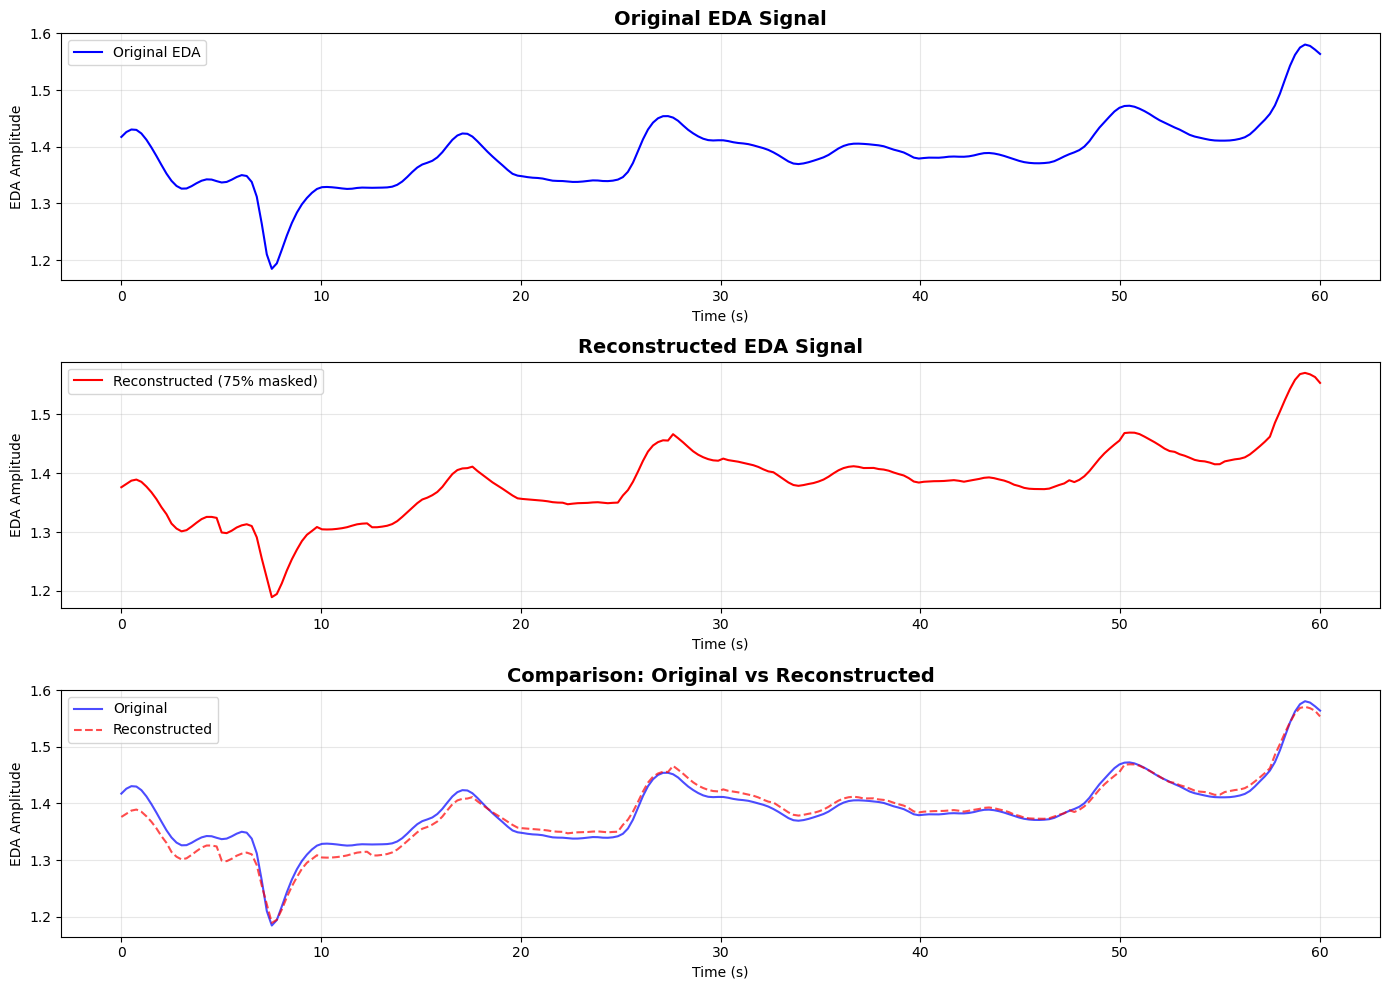


✓ Visualization complete!
Data source: Real EDA time series from CLUES dataset


In [40]:
# Select first sample for visualization
sample_idx = 0
original = batch_data[sample_idx, :, 0].cpu().numpy()
recon = reconstructed[sample_idx, :, 0].cpu().numpy()

# Create time axis
time_vis = np.linspace(0, 60, len(original))

# Create visualization
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Original signal
axes[0].plot(time_vis, original, 'b-', linewidth=1.5, label='Original EDA')
axes[0].set_title('Original EDA Signal', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('EDA Amplitude')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Reconstructed signal
axes[1].plot(time_vis, recon, 'r-', linewidth=1.5, label='Reconstructed (75% masked)')
axes[1].set_title('Reconstructed EDA Signal', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('EDA Amplitude')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Overlay comparison
axes[2].plot(time_vis, original, 'b-', linewidth=1.5, alpha=0.7, label='Original')
axes[2].plot(time_vis, recon, 'r--', linewidth=1.5, alpha=0.7, label='Reconstructed')
axes[2].set_title('Comparison: Original vs Reconstructed', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('EDA Amplitude')
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"\n✓ Visualization complete!")
print(f"Data source: Real EDA time series from CLUES dataset")

## 7. Batch Processing Example

Process multiple batches efficiently.

In [8]:
# Simulate processing multiple batches
num_batches = 5
batch_size = 16
all_embeddings = []

print(f"Processing {num_batches} batches of {batch_size} samples each...\n")

for i in range(num_batches):
    # Create batch
    batch = torch.randn(batch_size, seq_len, in_channels)
    
    # Extract embeddings
    emb = pipeline.embed(batch)
    all_embeddings.append(emb.cpu())
    
    print(f"  Batch {i+1}/{num_batches}: {emb.shape}")

# Concatenate all embeddings
all_embeddings = torch.cat(all_embeddings, dim=0)
print(f"\nTotal embeddings collected: {all_embeddings.shape}")
print(f"Total samples processed: {all_embeddings.shape[0]}")

Processing 5 batches of 16 samples each...

  Batch 1/5: torch.Size([16, 24, 512])
  Batch 2/5: torch.Size([16, 24, 512])
  Batch 3/5: torch.Size([16, 24, 512])
  Batch 4/5: torch.Size([16, 24, 512])
  Batch 5/5: torch.Size([16, 24, 512])

Total embeddings collected: torch.Size([80, 24, 512])
Total samples processed: 80
  Batch 5/5: torch.Size([16, 24, 512])

Total embeddings collected: torch.Size([80, 24, 512])
Total samples processed: 80


## 8. Embedding Analysis

Analyze the embedding space.

In [9]:
# Get embeddings for analysis
analysis_batch = torch.randn(50, seq_len, in_channels)
emb = pipeline.embed(analysis_batch).cpu()

# Flatten embeddings for analysis
emb_flat = emb.reshape(emb.shape[0], -1)

print(f"Embedding statistics:")
print(f"  Shape (per sample): {emb.shape[1:]}")
print(f"  Flattened shape: {emb_flat.shape}")
print(f"  Mean: {emb_flat.mean():.4f}")
print(f"  Std: {emb_flat.std():.4f}")
print(f"  Min: {emb_flat.min():.4f}")
print(f"  Max: {emb_flat.max():.4f}")

# Compute pairwise distances
from torch.nn.functional import pdist
distances = pdist(emb_flat)
print(f"\nPairwise distances:")
print(f"  Mean distance: {distances.mean():.4f}")
print(f"  Min distance: {distances.min():.4f}")
print(f"  Max distance: {distances.max():.4f}")

Embedding statistics:
  Shape (per sample): torch.Size([24, 512])
  Flattened shape: torch.Size([50, 12288])
  Mean: 0.0014
  Std: 0.1232
  Min: -2.5033
  Max: 3.1677

Pairwise distances:
  Mean distance: 17.7916
  Min distance: 15.0984
  Max distance: 20.8646


## Summary

This notebook demonstrated:

1. ✅ Loading pretrained models with `EdamamePipeline.from_pretrained()`
2. ✅ Extracting embeddings with `pipeline.embed()`
3. ✅ Accessing single sample embeddings: `pipeline.embed(batch)[0]`
4. ✅ Using masking for embedding extraction
5. ✅ Reconstructing signals with `pipeline.reconstruct()`
6. ✅ Visualizing results
7. ✅ Batch processing workflows
8. ✅ Embedding analysis

For more information, see:
- **API Documentation**: `edamame/pipeline/README.md`
- **Example Scripts**: `examples/pipeline_usage.py`
- **Test Suite**: `tests/test_pipeline.py`